In [4]:
import os

# List all files in the directory
data_dir_juno = 'Data_Files/Juno Data/Fenn'
files = os.listdir(data_dir_juno)

# Extract unique date prefixes (YYYYDDD) from filenames
date_prefixes = set()
for fname in files:
    # Assumes date prefix is the first 7 digits in the filename
    if len(fname) >= 7 and fname[:7].isdigit():
        date_prefixes.add(fname[:7])

date_prefixes = sorted(date_prefixes)
print(date_prefixes)


['2017192', '2017197', '2019092', '2021153', '2021154', '2021159']


In [9]:
import os
import glob
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datetime import datetime

DATA_DIR = 'Data_Files/Juno Data/Fenn'  # your data directory
PREFIXES = date_prefixes   # your list of YYYYDDD strings

def read_txt(fn):
    # 1) grab the header line and parse the energies
    with open(fn, 'r') as f:
        hdr = f.readline().lstrip().lstrip('#').split()
    # hdr looks like ['Time','/','Energy','(eV)','1.3685E+001',...]
    E = np.array(hdr[4:], dtype=float)   # skip the “Time / Energy (eV)”

    # 2) now read everything *after* that first line
    df = pd.read_csv(fn,
                     skiprows=1,           # skip your single header line
                     delim_whitespace=True,
                     header=None,
                     skip_blank_lines=True)

    # 3) parse the time column and the spectrogram values
    times = pd.to_datetime(df.iloc[:,0].str.strip(),
                           format='%Y-%m-%d/%H:%M:%S')
    S     = df.iloc[:,1:].values

    return times.values.astype('datetime64[s]'), E, S

def read_d2s(fn, convert_keV_to_eV=True):
    """
    Reads a .d2s spectrogram:
      - looks for the <yscan ... yTags="a,b,c..." /> line to get energies
      - collects every line starting with ":01:" as a data row
      - builds a DataFrame so columns never get mis-aligned
      - parses the time with pandas (so we get datetime64[ns])
      - converts to datetime64[s], so it matches the TXT reader
      - optionally converts keV→eV for direct comparison
    Returns:
       times: np.ndarray[datetime64[s]]    shape=(N,)
       E:     np.ndarray[float]            shape=(K,)
       S:     np.ndarray[float]            shape=(N,K)
    """
    ytags = None
    rows = []

    with open(fn, 'r') as f:
        for line in f:
            # 1) grab energies
            if '<yscan' in line and 'yTags=' in line:
                txt = re.search(r'yTags="([^"]+)"', line).group(1)
                # split on comma, strip spaces, parse floats
                ytags = np.array([float(x) for x in txt.split(',')])
            # 2) collect only the real data lines
            elif line.startswith(':01:'):
                # drop the ":01:" prefix and any leading whitespace
                rows.append(line[4:].strip().split())

    # --- sanity check ---
    if ytags is None:
        raise ValueError(f"No yTags line found in {fn}")

    # 3) build a DataFrame: column 0 is time, 1..K are fluxes
    df = pd.DataFrame(rows)
    # 4) parse times exactly
    times = pd.to_datetime(df.iloc[:,0],
                           format='%Y-%m-%dT%H:%M:%S.%f',
                           utc=False)
    # convert to seconds resolution to match your TXT reader
    times = times.values.astype('datetime64[s]')

    # 5) get the spectrogram array
    S = df.iloc[:,1:].astype(float).values

    # 6) convert energies if you want eV instead of keV
    E = ytags.copy()
    if convert_keV_to_eV:
        E *= 1e3

    return times, E, S

def plot_spectrogram(times, E, S, title):
    """
    Makes a time–energy spectrogram via pcolormesh.
    """
    T, Y = np.meshgrid(times.astype('datetime64[s]').astype(float), E)
    # note: pcolormesh wants x & y of shape (M+1,N+1) or like meshgrid transposed
    plt.figure(figsize=(10,4))
    plt.pcolormesh(times, E, S.T, shading='auto', cmap='jet',)
    plt.yscale('log')
    plt.ylabel('Energy (eV or keV)')
    plt.xlabel('Time')
    plt.title(title)
    plt.colorbar(label='Flux (c/s/ster/cm²/keV)')
    plt.tight_layout()

if __name__ == '__main__':
    for prefix in PREFIXES:
        # find all files for this day
        pattern_txt = os.path.join(DATA_DIR, f'{prefix}_*.txt')
        pattern_d2s = os.path.join(DATA_DIR, f'{prefix}_*.d2s')
        for fn in glob.glob(pattern_txt) + glob.glob(pattern_d2s):
            basename = os.path.basename(fn)
            if fn.endswith('.txt'):
                times, E, S = read_txt(fn)
            else:
                times, E, S = read_d2s(fn)
            # make your plot
            plot_spectrogram(times, E, S, title=basename)
            # save out to a figures directory
            outfig = os.path.join('Juno Figures', 'figures',
                                  basename.replace('.', '_') + '.png')
            os.makedirs(os.path.dirname(outfig), exist_ok=True)
            plt.savefig(outfig, dpi=200)
            plt.close()


/var/folders/fz/cnqc4h596ll_2kqzb_kkg3x40000gn/T/ipykernel_2709/2344396034.py:20: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_csv(fn,
/var/folders/fz/cnqc4h596ll_2kqzb_kkg3x40000gn/T/ipykernel_2709/2344396034.py:20: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_csv(fn,
/var/folders/fz/cnqc4h596ll_2kqzb_kkg3x40000gn/T/ipykernel_2709/2344396034.py:20: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_csv(fn,
/var/folders/fz/cnqc4h596ll_2kqzb_kkg3x40000gn/T/ipykernel_2709/2344396034.py:20: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_csv(fn,
/var/folders

2017-07-11 10:21:51.804 2017-07-11 16:41:10.955
Dataset: 'unknown_4Y_01' from group 'unknown_4Y' | i:0..22396
   Property: title | Magnetic Field from FGM in Planetocentric Coordinates%{xCacheResInfo}
   Property: sourceId | das2_bin_avgsec

   Data Dimension : mag
      Property: scaleType | linear
      Property: summary | The magnitude of the magnetic field.
      Property: label | |B| (nT)

      Variable: mag['center'][i] (float64) nT

   Data Dimension : x
      Property: scaleType | linear
      Property: summary | The X component of the magnetic field in the requested frame.
      Property: label | X!bPC!n (nT)

      Variable: x['center'][i] (float64) nT

   Data Dimension : y
      Property: scaleType | linear
      Property: summary | The Y component of the magnetic field in the requested frame.
      Property: label | Y!bPC!n (nT)

      Variable: y['center'][i] (float64) nT

   Data Dimension : z
      Property: scaleType | linear
      Property: summary | The Z component 

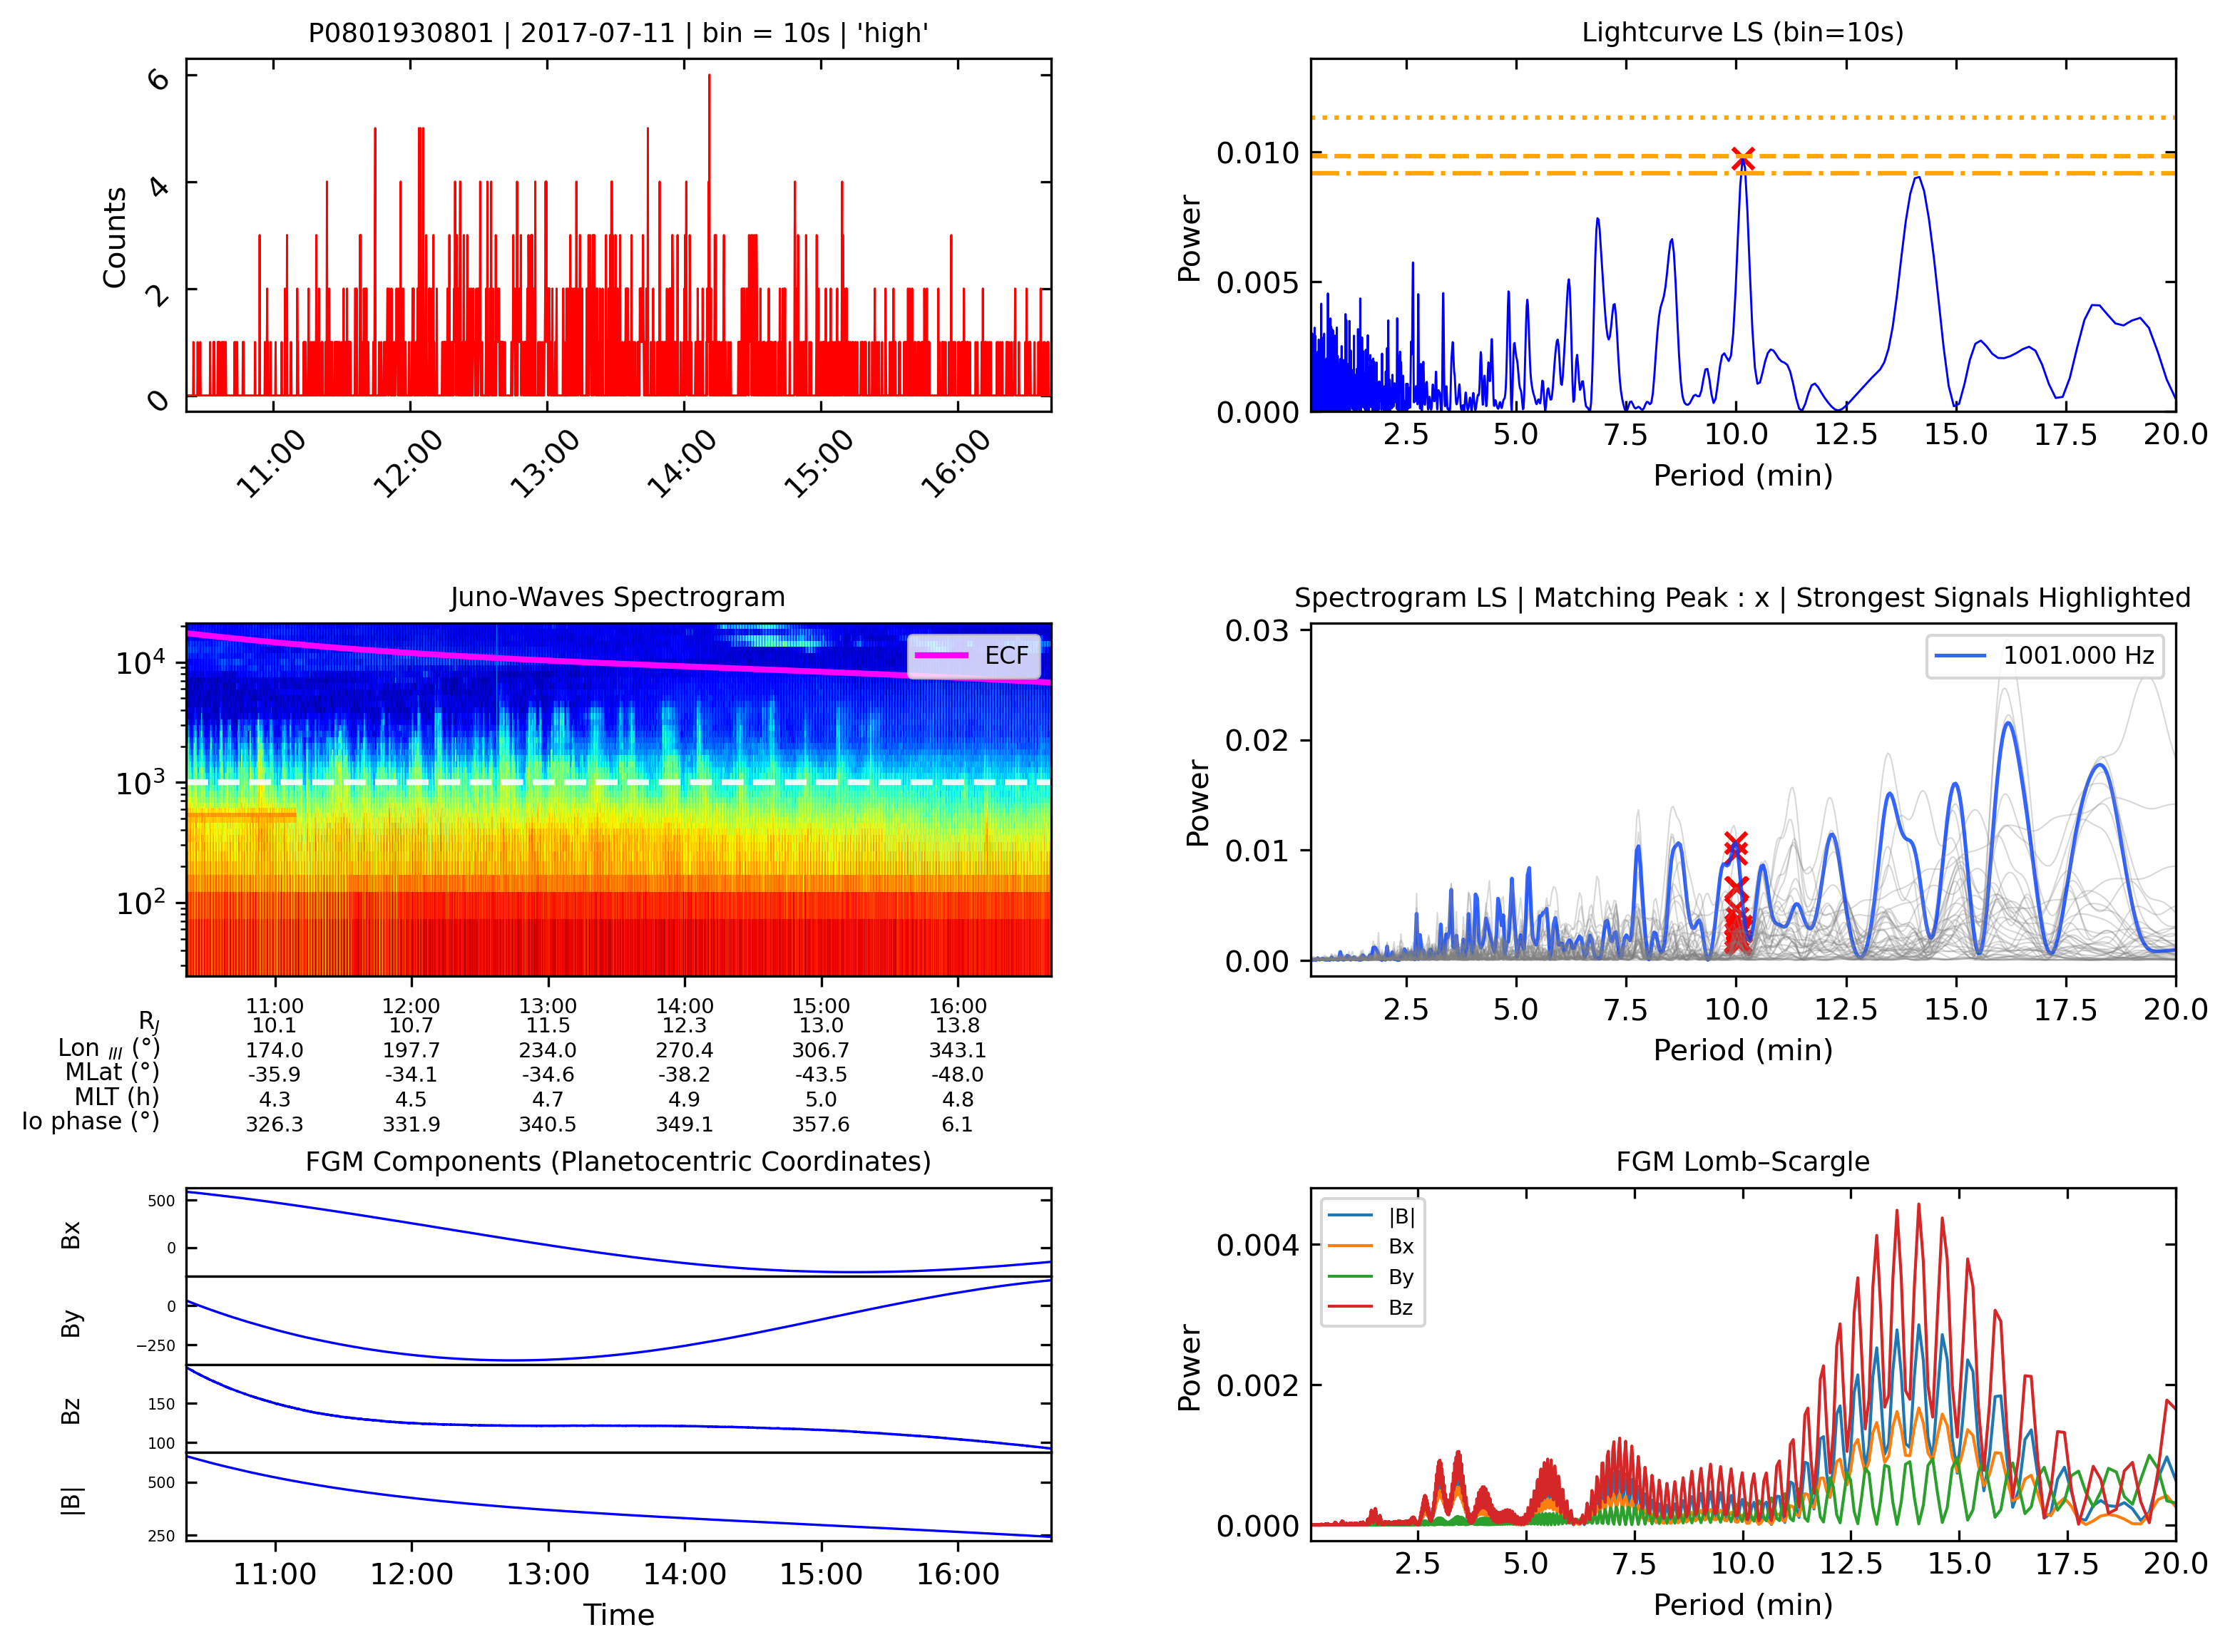

Finished processing P0801930801
2017-07-16 19:23:52.382 2017-07-17 01:42:55.417
Dataset: 'unknown_4Y_01' from group 'unknown_4Y' | i:0..22743
   Property: title | Magnetic Field from FGM in Planetocentric Coordinates%{xCacheResInfo}
   Property: sourceId | das2_bin_avgsec

   Data Dimension : mag
      Property: scaleType | linear
      Property: summary | The magnitude of the magnetic field.
      Property: label | |B| (nT)

      Variable: mag['center'][i] (float64) nT

   Data Dimension : x
      Property: scaleType | linear
      Property: summary | The X component of the magnetic field in the requested frame.
      Property: label | X!bPC!n (nT)

      Variable: x['center'][i] (float64) nT

   Data Dimension : y
      Property: scaleType | linear
      Property: summary | The Y component of the magnetic field in the requested frame.
      Property: label | Y!bPC!n (nT)

      Variable: y['center'][i] (float64) nT

   Data Dimension : z
      Property: scaleType | linear
      Prop

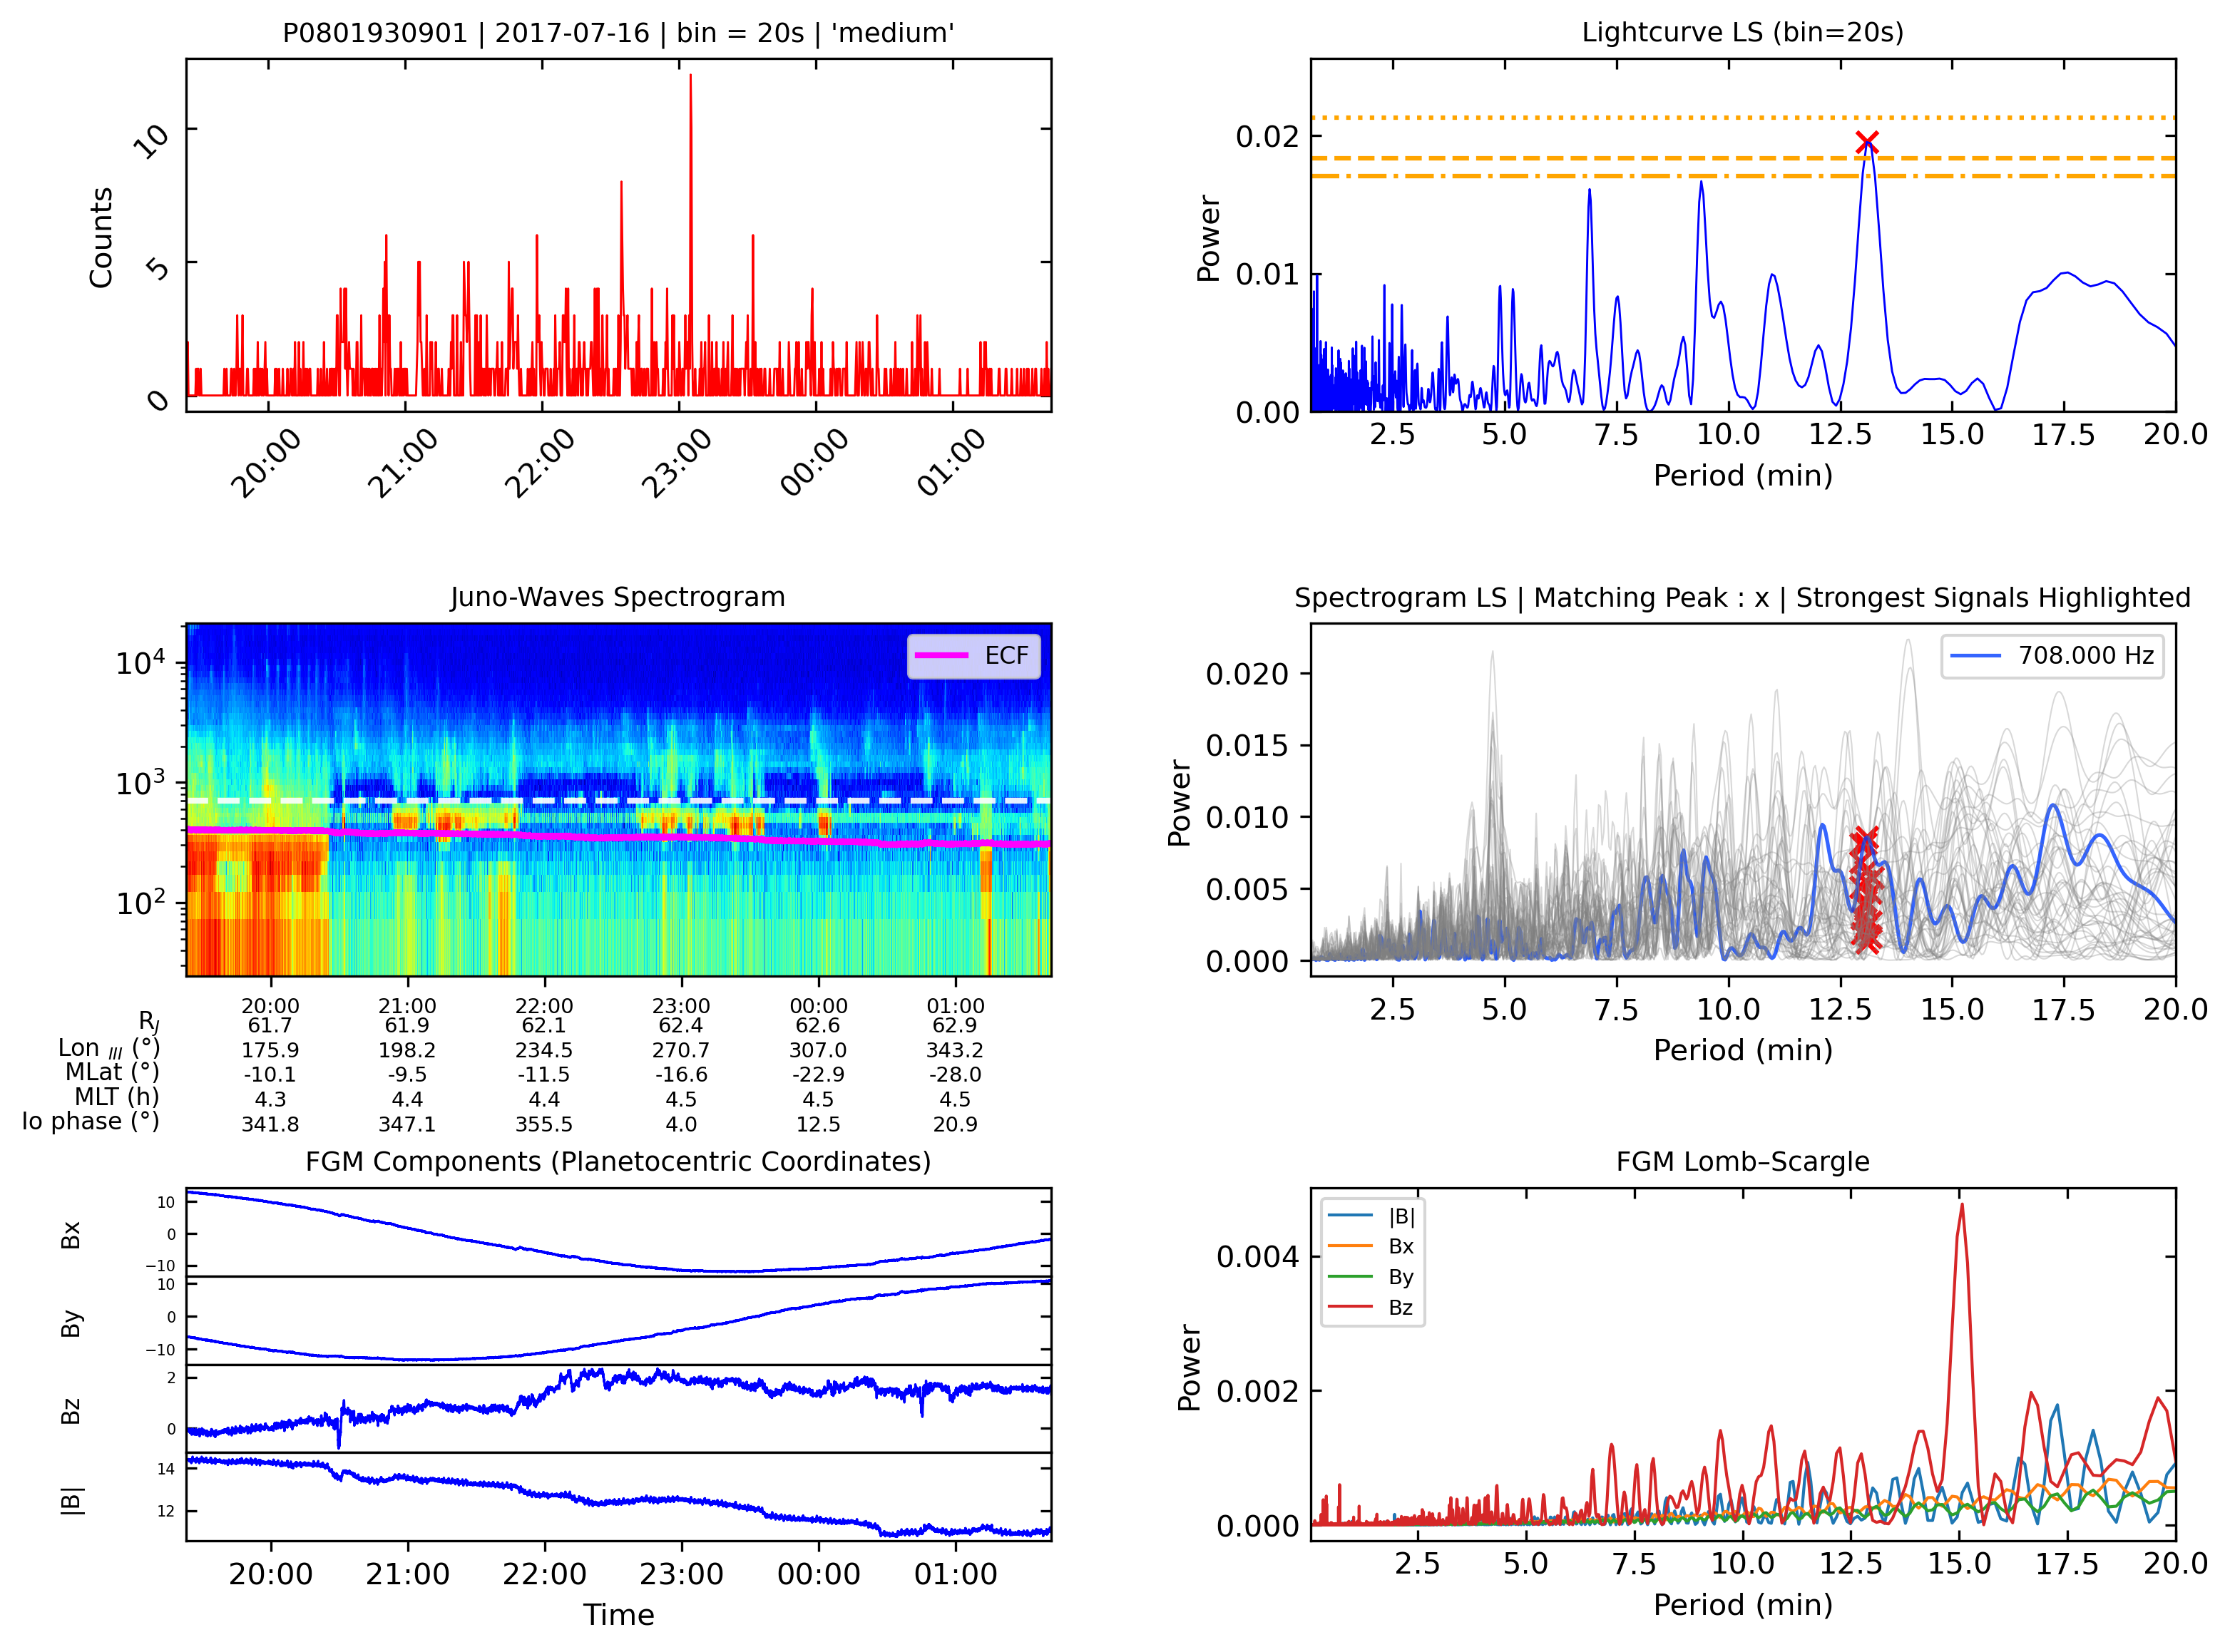

Finished processing P0801930901
2019-04-02 17:51:10.574 2019-04-02 22:16:31.607
Dataset: 'unknown_4Y_01' from group 'unknown_4Y' | i:0..15921
   Property: title | Magnetic Field from FGM in Planetocentric Coordinates%{xCacheResInfo}
   Property: sourceId | das2_bin_avgsec

   Data Dimension : mag
      Property: scaleType | linear
      Property: summary | The magnitude of the magnetic field.
      Property: label | |B| (nT)

      Variable: mag['center'][i] (float64) nT

   Data Dimension : x
      Property: scaleType | linear
      Property: summary | The X component of the magnetic field in the requested frame.
      Property: label | X!bPC!n (nT)

      Variable: x['center'][i] (float64) nT

   Data Dimension : y
      Property: scaleType | linear
      Property: summary | The Y component of the magnetic field in the requested frame.
      Property: label | Y!bPC!n (nT)

      Variable: y['center'][i] (float64) nT

   Data Dimension : z
      Property: scaleType | linear
      Prop

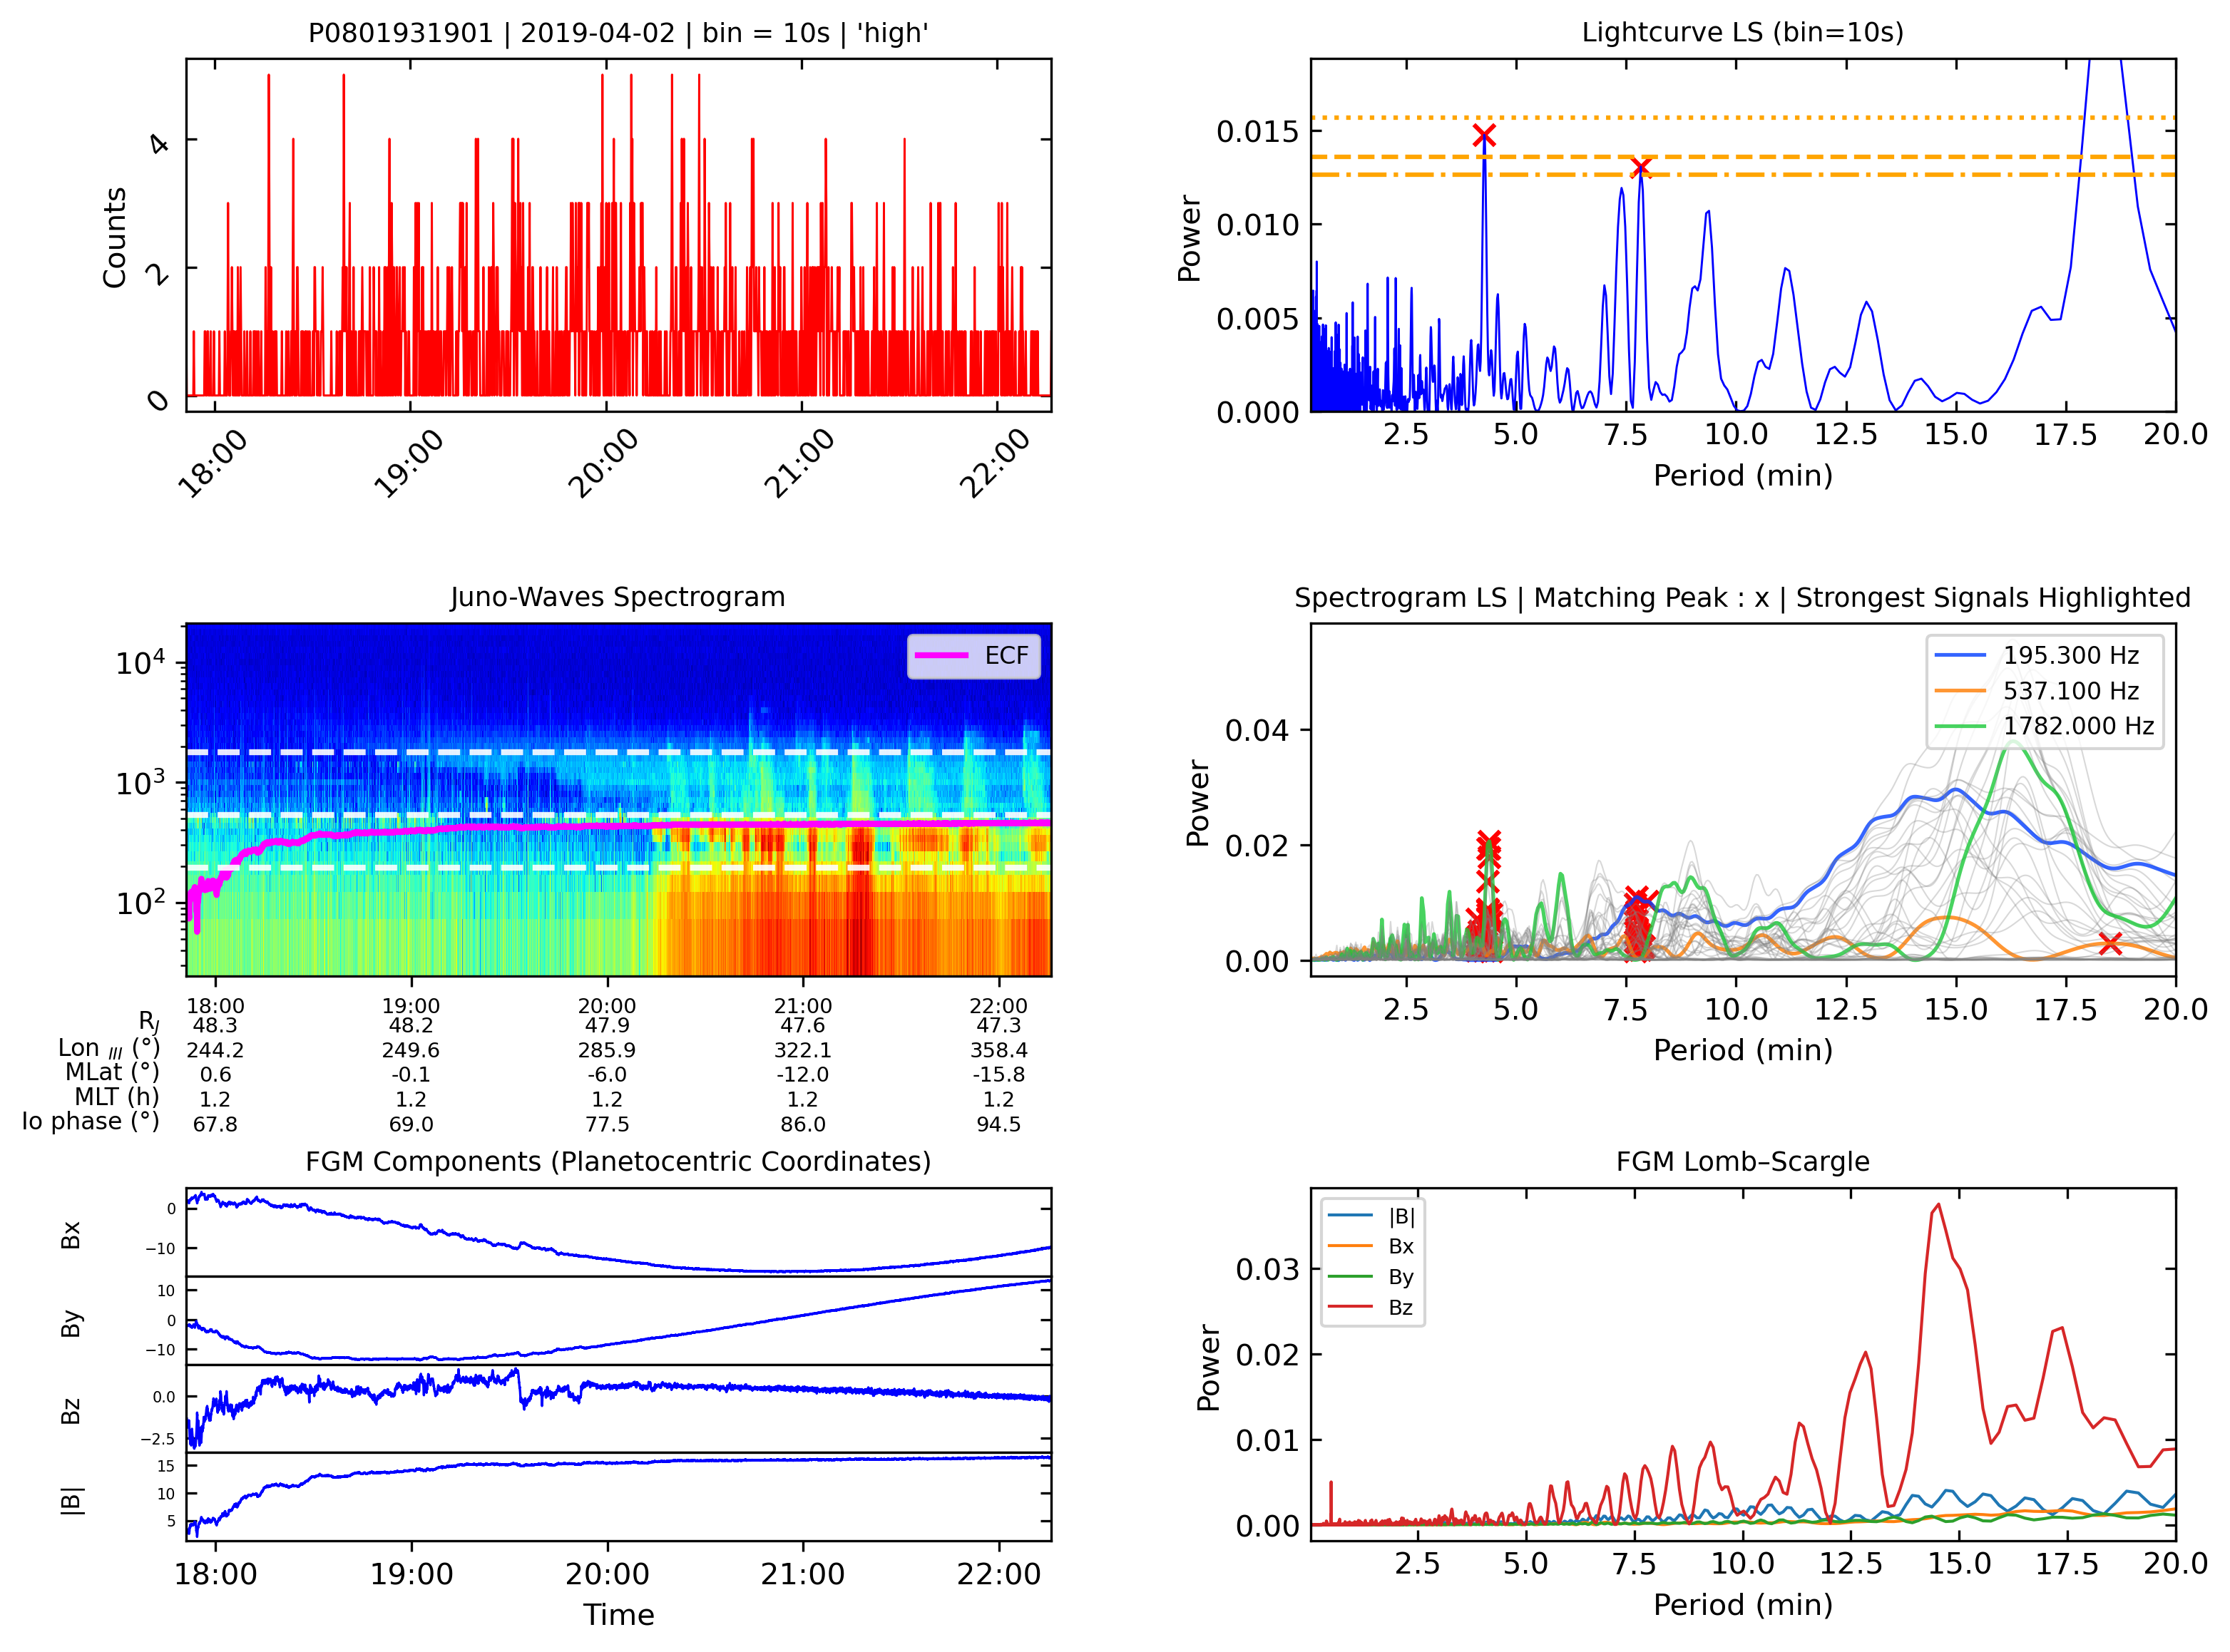

Finished processing P0801931901
2021-06-03 03:51:24.234 2021-06-03 07:47:39.665
Dataset: 'unknown_4Y_01' from group 'unknown_4Y' | i:0..14176
   Property: title | Magnetic Field from FGM in Planetocentric Coordinates%{xCacheResInfo}
   Property: sourceId | das2_bin_avgsec

   Data Dimension : mag
      Property: scaleType | linear
      Property: summary | The magnitude of the magnetic field.
      Property: label | |B| (nT)

      Variable: mag['center'][i] (float64) nT

   Data Dimension : x
      Property: scaleType | linear
      Property: summary | The X component of the magnetic field in the requested frame.
      Property: label | X!bPC!n (nT)

      Variable: x['center'][i] (float64) nT

   Data Dimension : y
      Property: scaleType | linear
      Property: summary | The Y component of the magnetic field in the requested frame.
      Property: label | Y!bPC!n (nT)

      Variable: y['center'][i] (float64) nT

   Data Dimension : z
      Property: scaleType | linear
      Prop

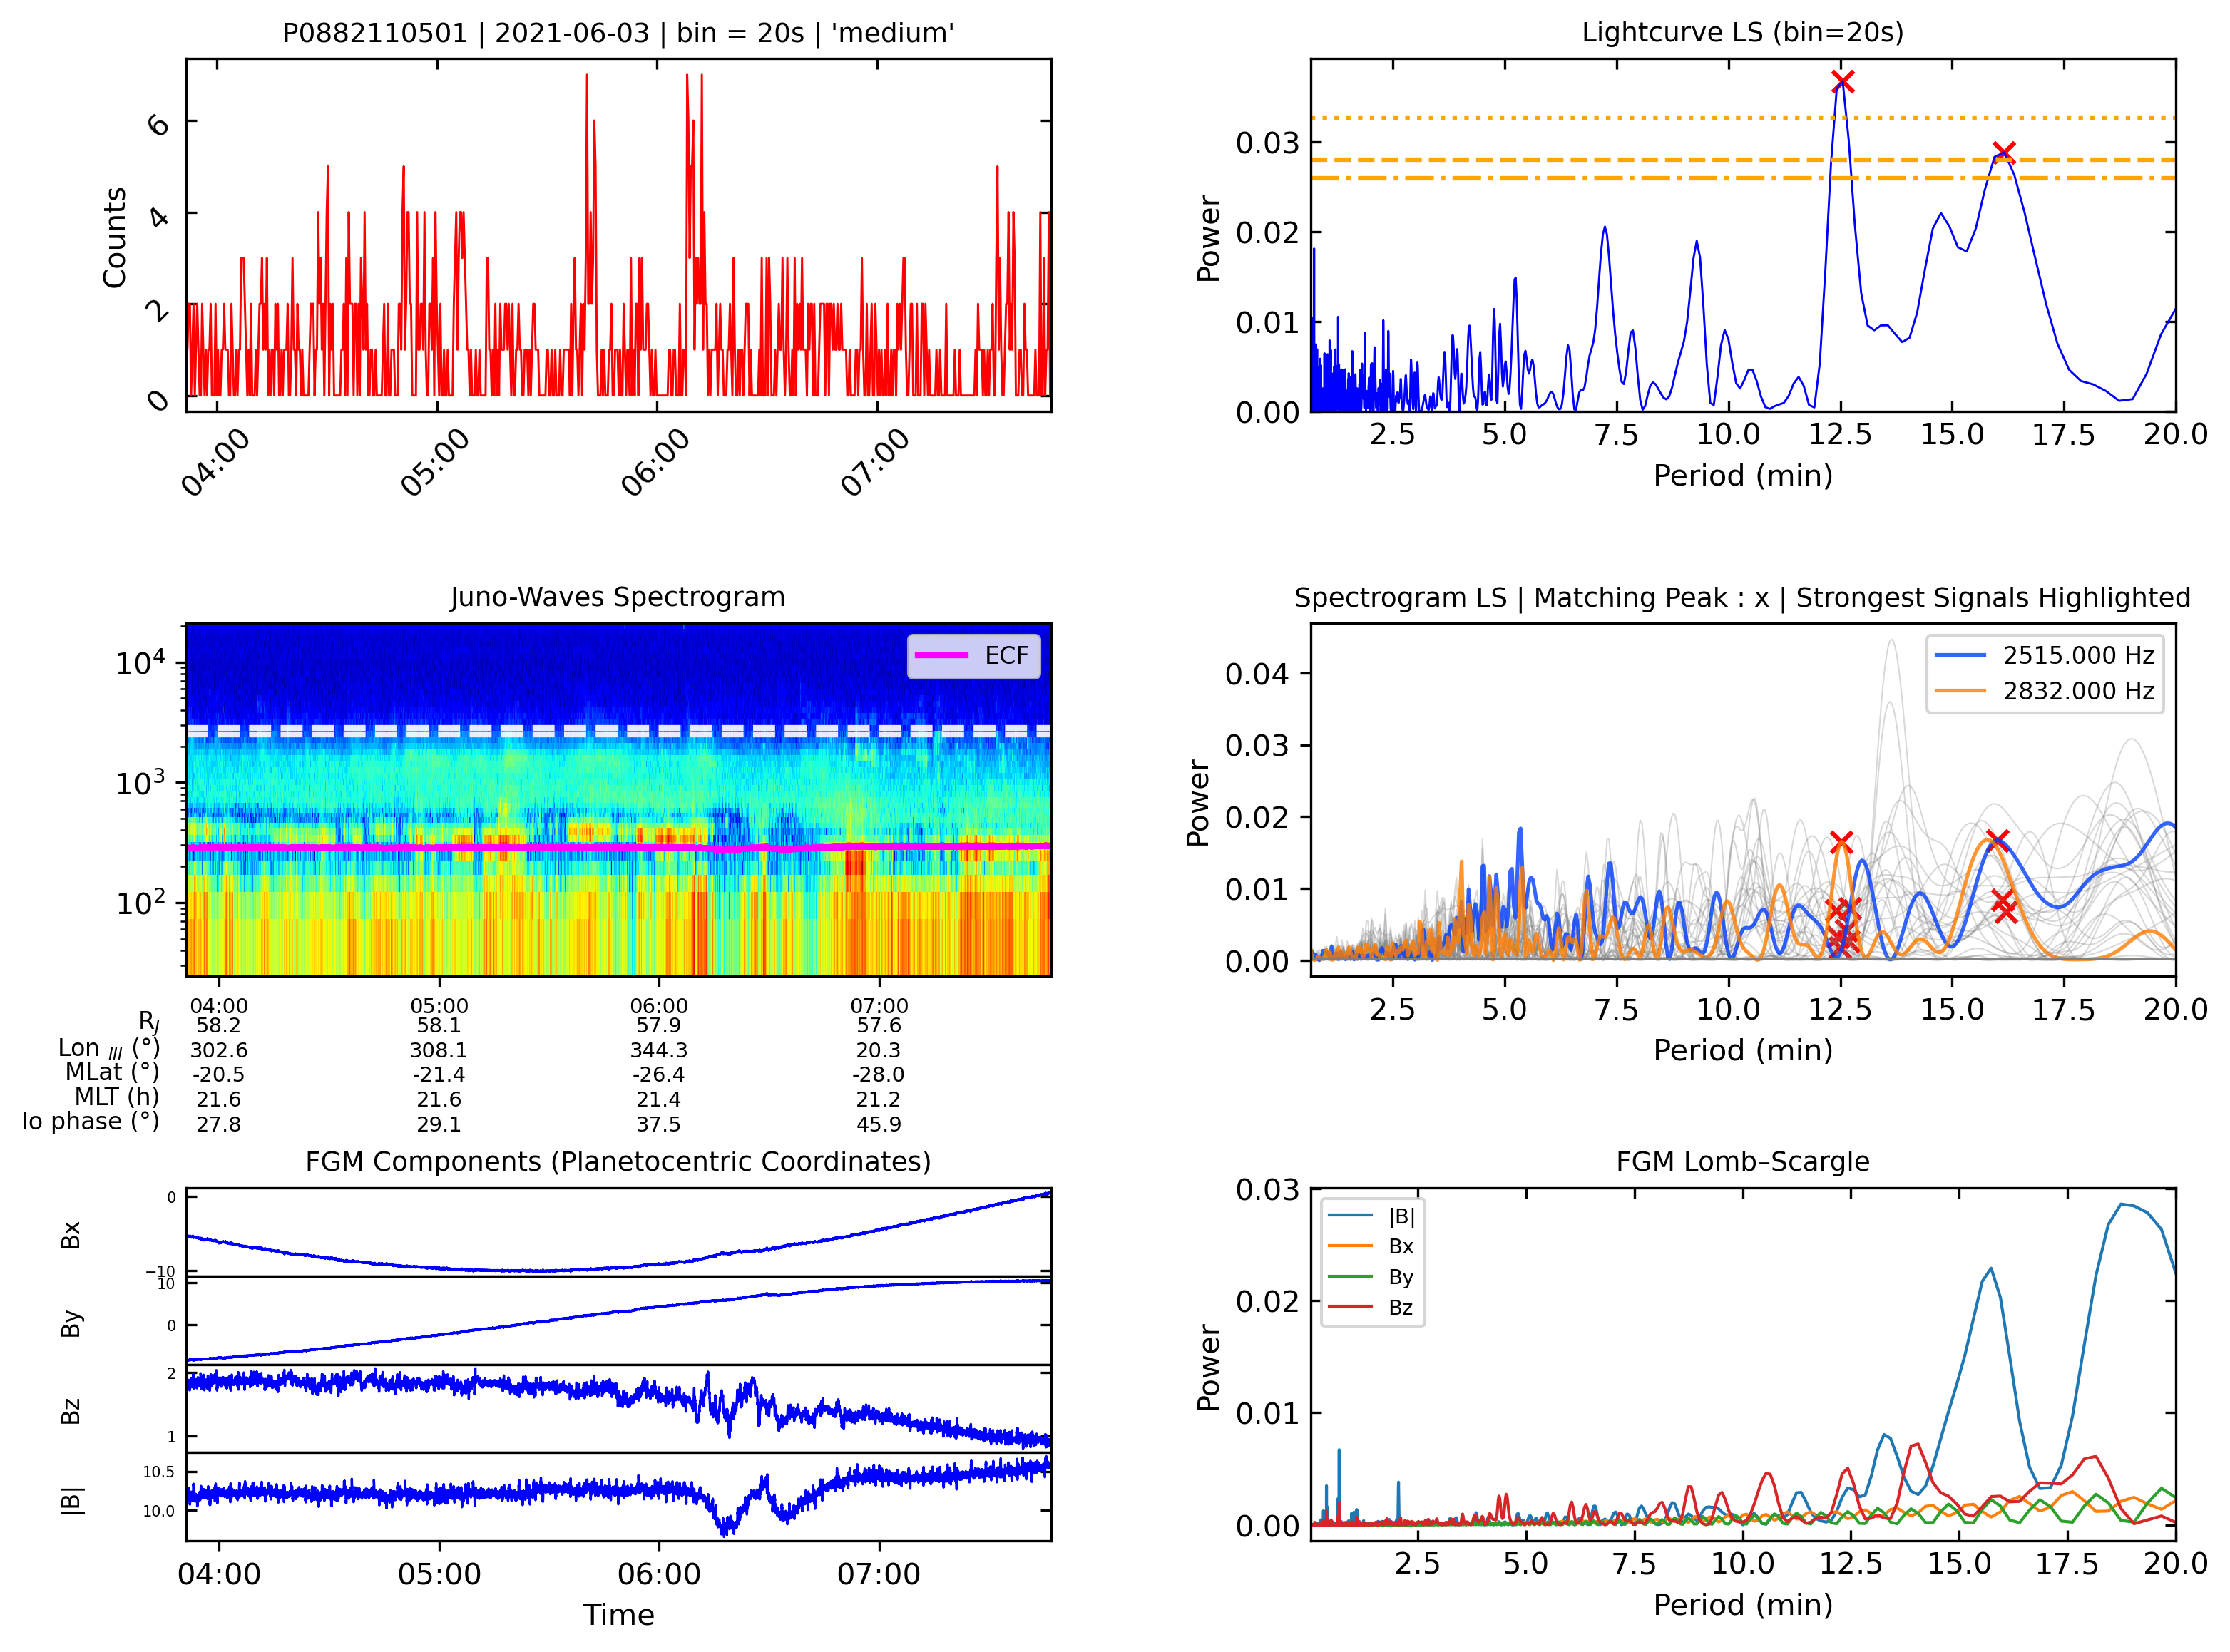

Finished processing P0882110501
2021-06-08 22:49:03.969 2021-06-09 05:07:34.550
Dataset: 'unknown_4Y_01' from group 'unknown_4Y' | i:0..22710
   Property: title | Magnetic Field from FGM in Planetocentric Coordinates%{xCacheResInfo}
   Property: sourceId | das2_bin_avgsec

   Data Dimension : mag
      Property: scaleType | linear
      Property: summary | The magnitude of the magnetic field.
      Property: label | |B| (nT)

      Variable: mag['center'][i] (float64) nT

   Data Dimension : x
      Property: scaleType | linear
      Property: summary | The X component of the magnetic field in the requested frame.
      Property: label | X!bPC!n (nT)

      Variable: x['center'][i] (float64) nT

   Data Dimension : y
      Property: scaleType | linear
      Property: summary | The Y component of the magnetic field in the requested frame.
      Property: label | Y!bPC!n (nT)

      Variable: y['center'][i] (float64) nT

   Data Dimension : z
      Property: scaleType | linear
      Prop

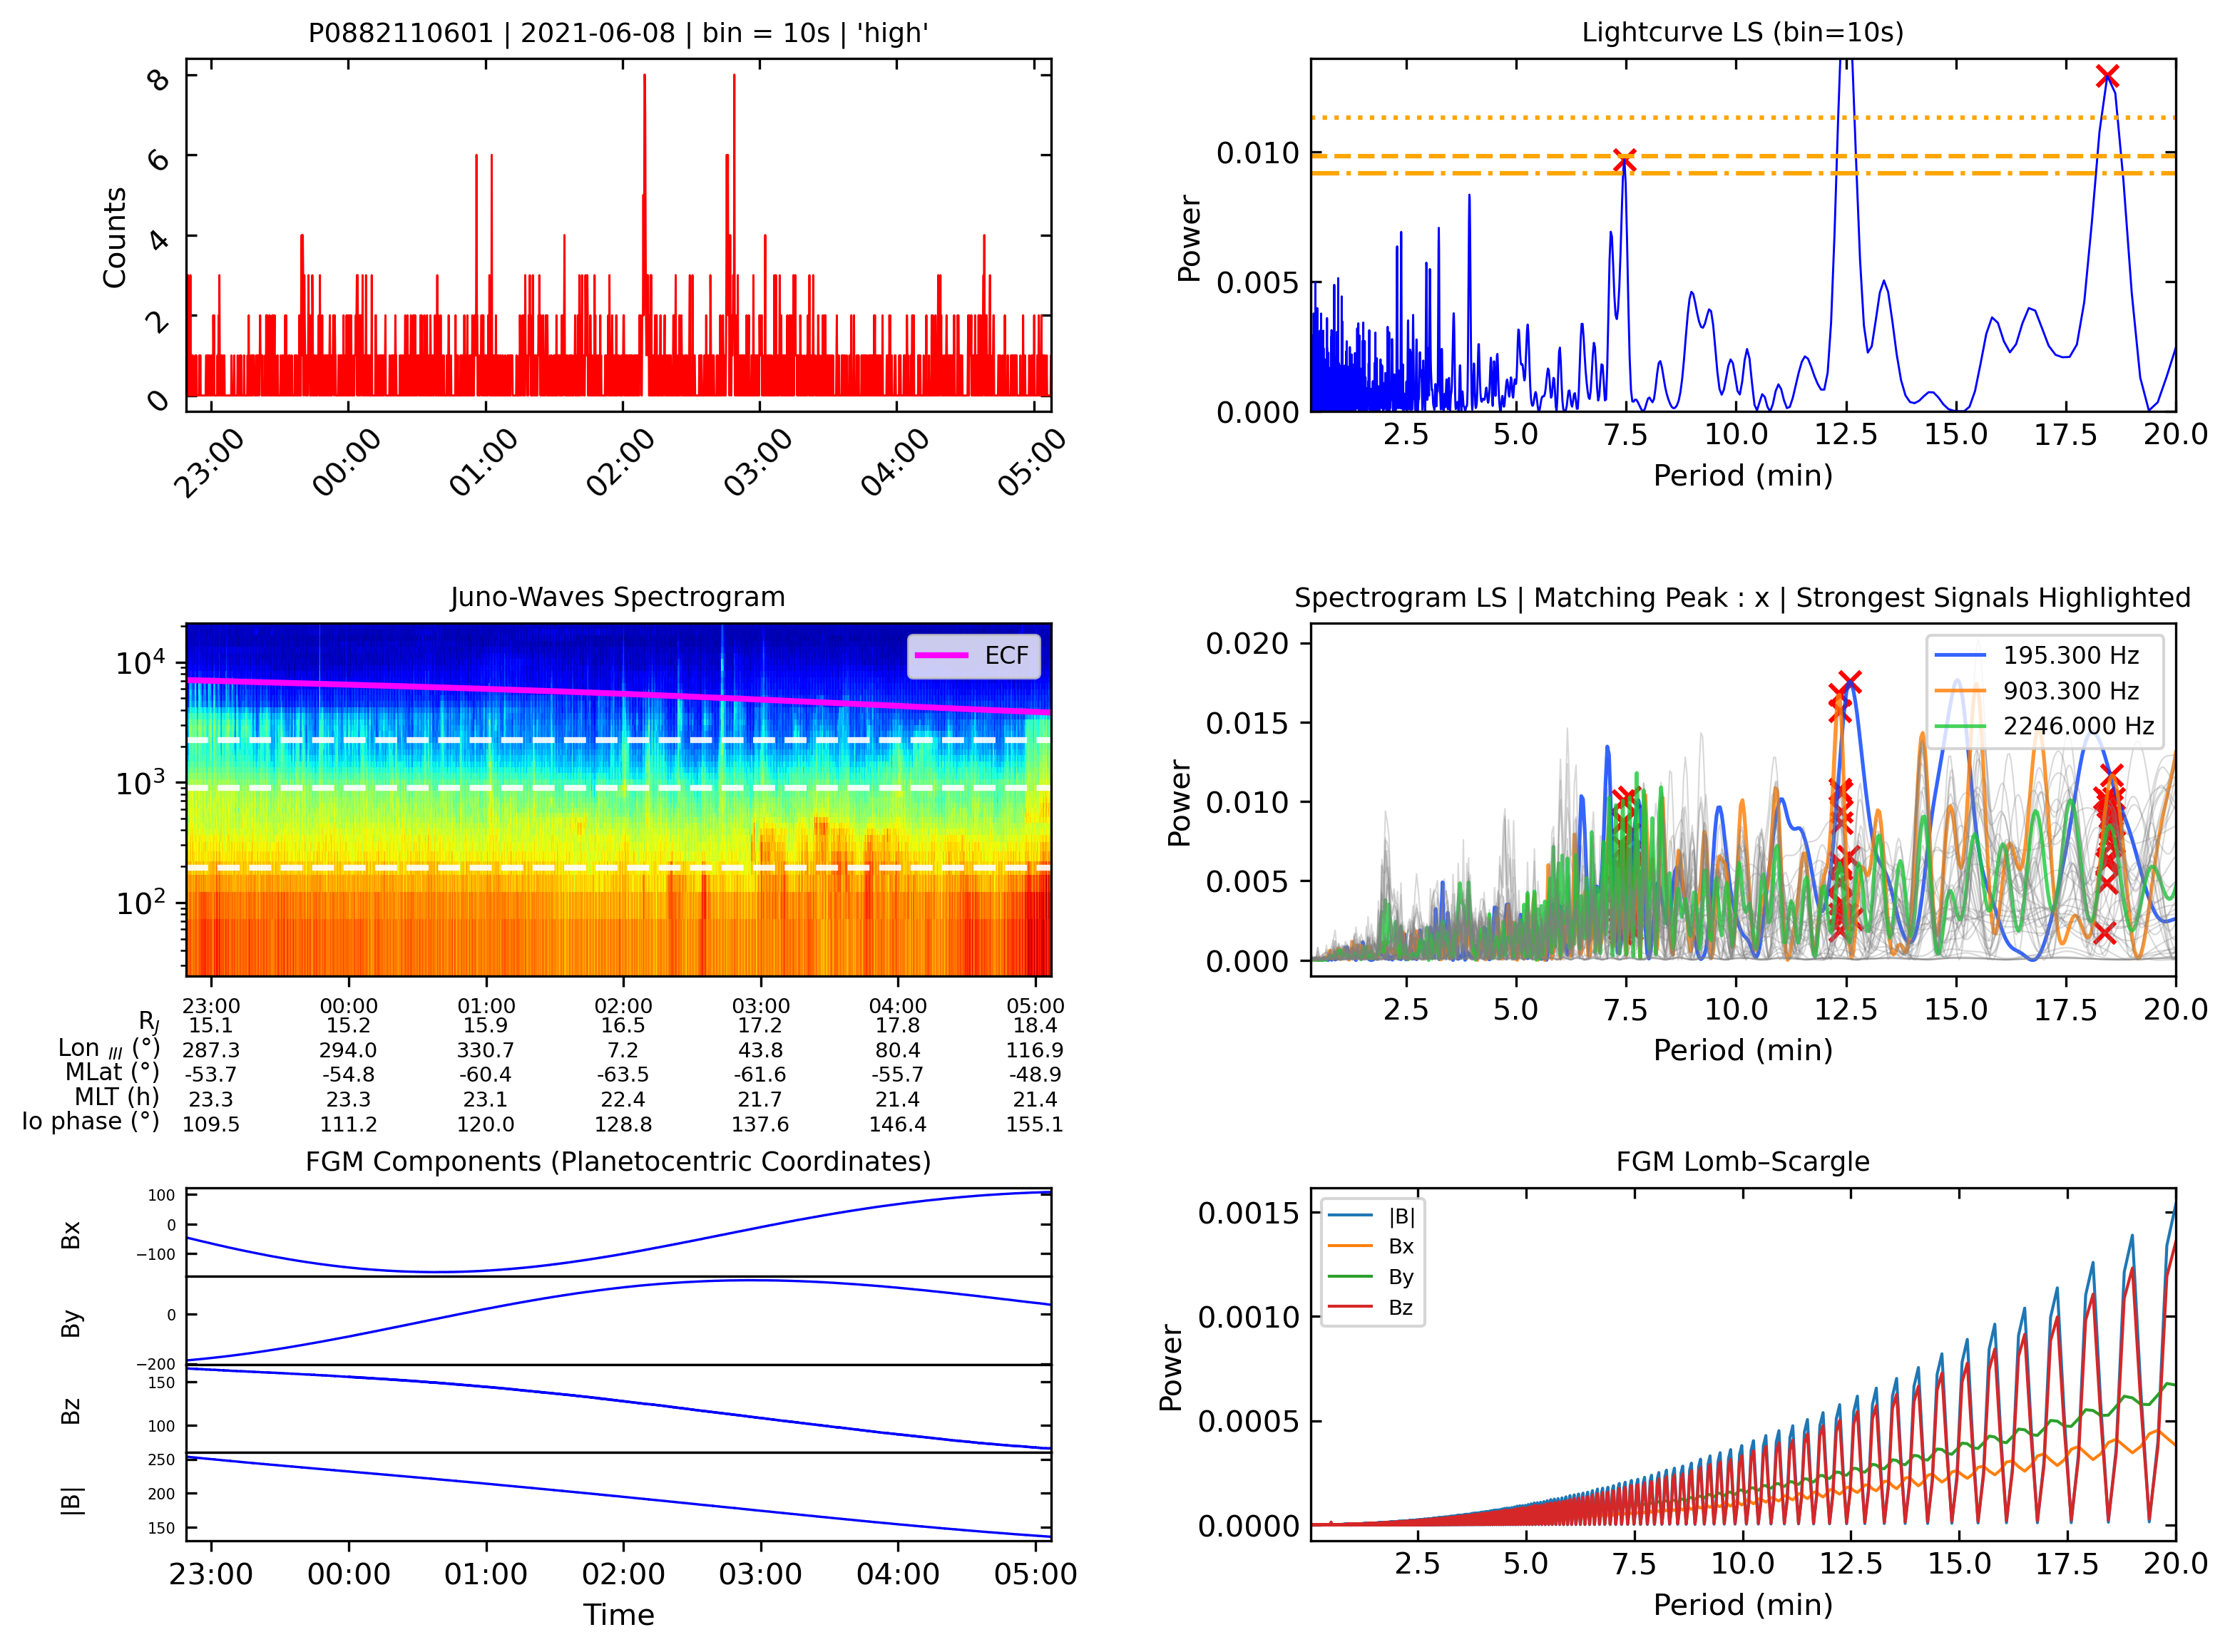

Finished processing P0882110601
All segments processed.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator
import matplotlib.dates as mdates

from astropy.table import Table
from astropy.time import Time
from astropy.timeseries import LombScargle
from astropy.coordinates import get_body_barycentric, solar_system_ephemeris
from astropy.constants import c
import astropy.units as u

from matplotlib.dates import DateFormatter, HourLocator, MinuteLocator
from matplotlib.colors import LogNorm

from scipy.signal import find_peaks
import seaborn as sns 
import das2
import warnings
warnings.filterwarnings("ignore")

# ─── GLOBAL SETTINGS ───────────────────────────────────────────────────────────────────────
tick_interval_h = 1      # major tick every 1 hour
minor_interval_h = 1     # minor tick every 1 hour
tol = 10 / 60 # Minutes of tolerance for matching periods

ident = ['P0801930801', 'P0801930901', 'P0801931901', 'P0882110501', 'P0882110601']
TARGET_SEGMENTS = { 'P0801930801': 2, 'P0801930901': 1, 'P0801931901': 3, 'P0882110501': 3, 'P0882110601': 5}


base_bin_size = 10       # seconds; used only to categorise first
data_dir      = 'Data_Files/Fenn_Data/'

# ─── DICTIONARY OF (obs_id → 1-BASED_SEGMENT_INDEX) ────────────────────────────────────────
# Only the specified segment number (1-based) for each obs_id will be plotted.
# If an obs_id is not in this dict, all its segments are plotted.


#ident = ['P0882110501']
#TARGET_SEGMENTS = {'P0882110501': 2}

# ─── UTILITY FUNCTIONS ─────────────────────────────────────────────────────────────────────
def get_das2_data(start_time, end_time):
    """
    Fetch DAS2 spectrogram for [start_time, end_time] (strings in ISO);
    return (vX, vY, vZ).
    """
    st = Time(start_time).datetime.strftime('%Y-%m-%dT%H:%M')
    et = Time(end_time).datetime.strftime('%Y-%m-%dT%H:%M')
    src = das2.get_source('site:/uiowa/juno/wav/survey/das2')
    ds  = src.get({'time': (st, et, 4.0)})[0]
    return ds['Time']['center'], ds['frequency']['center'], ds['spec_dens']['center']

def get_fgm_data(start_iso, end_iso, dt_sec):
    """
    Fetch Juno FGM field magnitude & components for [start_iso, end_iso];
    returns (times, Bmag, Bx, By, Bz).
    """
    t0 = start_iso.replace(' ', 'T')
    t1 = end_iso.replace(' ', 'T')
    src = das2.get_source('tag:das2.org,2012:site:/uiowa/juno/fgm/magcomponents/das2')
    ds  = src.get({'time': (t0, t1, dt_sec), 'coord.eq.pc' : True})[0]
    print(ds)
    t    = ds['time']['center'].array
    Bmag = ds['mag']['center'].array
    Bx   = ds['x']['center'].array
    By   = ds['y']['center'].array
    Bz   = ds['z']['center'].array
    print(t)
    print(Bmag)
    return t, Bmag, Bx, By, Bz

def load_combined_times(obs_id, data_dir):
    """
    Read all three EPIC cameras, correct for Jupiter–Earth light travel time,
    and return two arrays:
      • times_datetime: numpy array of Python datetimes
      • times_cxcsec:   numpy array of CXC seconds (float)
    """
    files = [f'{data_dir}EPIC_{obs_id}_{cam}_North_RFT.fit' for cam in ['PN', 'M1', 'M2']]
    list_dt = []
    list_cxc = []

    for file in files:
        data = Table.read(file, format="fits")
        
        t = Time(data['TIME'], format='cxcsec', scale='tt')
        with solar_system_ephemeris.set('de432s'):
            jup = get_body_barycentric('jupiter', t)
            xmm = get_body_barycentric('earth', t)  # approximate XMM as Earth-based

        distance     = (jup - xmm).norm()                   # in AU
        light_time_s = (distance.to('m') / c).to('s').value  # in seconds
        
        corrected_t = t - light_time_s * u.s

        list_dt.append(corrected_t.datetime)
        list_cxc.append(corrected_t.cxcsec)

    return np.hstack(list_dt), np.hstack(list_cxc)


def find_gaps(times_cxcsec, threshold=3600):
    """
    Identify indices where the gap between consecutive times > threshold seconds.
    Returns (list_of_(gap_start, gap_end), array_of_gap_indices).
    """
    dt      = np.diff(times_cxcsec)
    indices = np.where(dt > threshold)[0]
    gaps    = [(times_cxcsec[i], times_cxcsec[i+1]) for i in indices]
    return gaps, indices


def bin_photon_times(photon_times, bin_size):
    """
    Bin photon_times (given in CXC seconds) into bins of width=bin_size (seconds).
    Returns (bin_centers, counts).
    """
    start = photon_times.min()
    end   = photon_times.max()
    bins  = np.arange(start, end + bin_size, bin_size)
    counts, bin_edges = np.histogram(photon_times, bins=bins)
    centers = bin_edges[:-1] + (bin_size / 2)
    return centers, counts


def categorize_segment(counts, low_thresh=300, high_thresh=1000):
    """
    Given a 1D counts array, sum it and decide:
      total < low_thresh   → 'low'
      low_thresh ≤ total < high_thresh → 'medium'
      total ≥ high_thresh  → 'high'
    """
    total = np.sum(counts)
    if total < low_thresh:
        return 'low'
    elif total < high_thresh:
        return 'medium'
    else:
        return 'high'


def dynamic_bin_size(category, base_bin=120):
    """
    Return an integer bin-size (in seconds) depending on category:
      'low'    →  base_bin × 4
      'medium' →  base_bin × 2
      'high'   →  base_bin
    """
    if category == 'low':
        return base_bin * 4
    elif category == 'medium':
        return base_bin * 2
    else:
        return base_bin


# ─── LIGHTCURVE‐RELATED FUNCTIONS ───────────────────────────────────────────────────────────

def prepare_segment_bins(raw_segment, base_bin):
    """
    1) Do an initial bin with base_bin solely to categorise the segment.
    2) Call categorize_segment(...) on that binned counts.
    3) Compute seg_bin = dynamic_bin_size(category, base_bin).
    4) Re‐bin raw_segment with seg_bin; return (seg_bin, hist_centers, hist_counts, category).
    """
    _, counts0 = bin_photon_times(raw_segment, base_bin)
    category   = categorize_segment(counts0)

    seg_bin = dynamic_bin_size(category, base_bin)
    hist_centers, hist_counts = bin_photon_times(raw_segment, seg_bin)
    return seg_bin, hist_centers, hist_counts, category


def compute_lightcurve_ls(hist_centers, hist_counts, seg_bin):
    """
    Compute LS periodogram for a lightcurve binned at seg_bin s, *only* between
    periods [2 × seg_bin, 20 minutes]. Returns:
      (period_lc, power_lc, fap10, fap05, fap01)
    where period_lc is in minutes, and fapX are power‐threshold scalars.
    """
    shortest_period = 2 * seg_bin        # seconds
    longest_period  = 20 * 60            # 1200 seconds

    freq_max = 1.0 / shortest_period     # highest frequency (Hz)
    freq_min = 1.0 / longest_period      # lowest frequency  (Hz)

    ls_lc = LombScargle(hist_centers, hist_counts)
    freq_lc, power_lc = ls_lc.autopower(
        minimum_frequency = freq_min,
        maximum_frequency = freq_max
    )

    period_lc = 1.0 / freq_lc / 60.0

    fap10 = ls_lc.false_alarm_level(
        0.10,
        minimum_frequency = freq_min,
        maximum_frequency = freq_max
    )
    fap05 = ls_lc.false_alarm_level(
        0.05,
        minimum_frequency = freq_min,
        maximum_frequency = freq_max
    )
    fap01 = ls_lc.false_alarm_level(
        0.01,
        minimum_frequency = freq_min,
        maximum_frequency = freq_max
    )

    return period_lc, power_lc, fap10, fap05, fap01


def plot_lightcurve_subplot(ax, hist_centers, hist_counts, seg_bin, category,
                            obs_id, start_iso, end_iso):
    """
    Plot the binned lightcurve (with start/end ISO in the title).
    """
    hist_dt = Time(hist_centers, format='cxcsec').datetime
    ax.plot(hist_dt, hist_counts, c='red', lw=0.7)

    # Title shows obs_id and ISO‐span, rather than “Seg #”
    title = f"{obs_id} | {start_iso[:10]} | bin = {seg_bin}s | {category!r}"
    ax.set_title(title, fontsize=9)

    ax.xaxis.set_major_locator(HourLocator(interval=1))
    ax.xaxis.set_major_formatter(DateFormatter('%H:%M'))
    ax.tick_params(rotation=45, direction='in', top=True, right=True)
    ax.set_ylabel("Counts")
    ax.set_xlim(hist_dt[0], hist_dt[-1])


def plot_lc_ls_subplot(ax, period_lc, power_lc, fap10, fap05, fap01, seg_bin):
    """
    Plot the LC Lomb–Scargle periodogram (draw FAP lines, mark peaks > 5% FAP).
    """
    ax.plot(period_lc, power_lc, lw=0.7, c='blue')
    ax.set_xlim(2 * seg_bin / 60.0, 20.0)  # in minutes

    ax.axhline(fap10, linestyle='-.', color='orange', label='10% FAP')
    ax.axhline(fap05, linestyle='--', color='orange', label='5% FAP')
    ax.axhline(fap01, linestyle=':',  color='orange', label='1% FAP')

    peaks = []
    for i in range(1, len(power_lc) - 1):
        if (
            (power_lc[i] > fap10) and
            (power_lc[i] > power_lc[i - 1]) and
            (power_lc[i] > power_lc[i + 1])
        ):
            peaks.append(i)
    peaks = np.array(peaks, dtype=int)

    if peaks.size > 0:
        ax.scatter(
            period_lc[peaks],
            power_lc[peaks],
            marker='x', color='red', s=50,
            label='LC peaks > 10% FAP'
        )

    ax.set_title(f"Lightcurve LS (bin={seg_bin}s)", fontsize=9)
    ax.set_xlabel("Period (min)")
    ax.set_ylabel("Power")
    ax.tick_params(direction='in', top=True, right=True)
    ax.set_ylim(0, 1.2 * fap01)
    #ax.legend(fontsize=8, loc='upper right')


# ─── SPECTROGRAM‐RELATED FUNCTIONS ─────────────────────────────────────────────────────────

def plot_spectrogram_subplot(ax, start_iso, end_iso):
    """
    Plot DAS2 spectrogram for time span [start_iso, end_iso], then overlay ephemeris rows.
    Returns (vX, vY, vZ, t_flat, dt_sec).
    """
    vX, vY, vZ = get_das2_data(start_iso, end_iso)
    t_spec = vX.array
    f_spec = vY.array
    S_spec = vZ.array

    if t_spec.ndim == 2:
        t_flat = t_spec[:, 0]
    else:
        t_flat = t_spec

    ax.set_xlim(t_flat[0], t_flat[-1])
    if np.issubdtype(t_flat.dtype, np.datetime64):
        dt_sec = int((t_flat[1] - t_flat[0]) / np.timedelta64(1, 's'))
    else:
        dt_sec = float(t_flat[1] - t_flat[0])

    ax.xaxis.set_major_locator(HourLocator(interval=tick_interval_h))
    ax.xaxis.set_minor_locator(HourLocator(interval=minor_interval_h))
    ax.xaxis.set_major_formatter(DateFormatter('%H:%M'))
    ax.tick_params(axis='x', which='minor', length=4)
    ax.tick_params(axis='x', which='major', labelsize=7)

    pcm = ax.pcolormesh(
        t_spec, f_spec, S_spec,
        norm=LogNorm(S_spec.min(), S_spec.max()),
        cmap='jet'
    )
    ax.set_yscale('log')
    ax.set_title("Juno-Waves Spectrogram", fontsize=9)

    start_iso_temp = start_iso.replace(' ', 'T')
    end_iso_temp = end_iso.replace(' ', 'T')
    efc_source = das2.get_source('tag:das2.org,2012:site:/uiowa/juno/fgm/electroncyclotron/das2')
    ds_efc = efc_source.get({'time': (start_iso_temp, end_iso_temp, dt_sec)})[0]
    efc_freq = ds_efc['fce']['center'].array
    efc_time = ds_efc['time']['center'].array
    ax.plot(efc_time, efc_freq, color='magenta', linewidth=2, label='ECF')
    ax.legend(fontsize=7, loc='upper right')
    try:
        eph_src = das2.get_source(
            'tag:das2.org,2012:site:/uiowa/juno/ephemeris/jovicentric/das2'
        )
        ds_eph = eph_src.get({'time': (start_iso, end_iso, dt_sec)})[0]

        rad   = ds_eph['radius']['center'].array
        lon3  = ds_eph['long']['center'].array
        mlatE = ds_eph['mlat']['center'].array
        mltE  = ds_eph['mlt']['center'].array
        ioE   = ds_eph['io_phase']['center'].array

        if mltE.dtype.kind == 'm':
            mltE = (mltE / np.timedelta64(1, 'h')).astype(float)

        t0  = t_flat[0]
        t1  = t_flat[-1]
        t0h = t0.astype('datetime64[h]')
        t1h = t1.astype('datetime64[h]') + np.timedelta64(1, 'h')
        major_ticks_dt = np.arange(
            t0h, t1h, np.timedelta64(tick_interval_h, 'h')
        )
        idx_eph = [np.argmin(np.abs(t_flat - mt)) for mt in major_ticks_dt]

        row_lbls = ["R$_J$", "Lon $_{III}$ (°)", "MLat (°)", "MLT (h)", "Io phase (°)"]
        row_vals = [
            rad[idx_eph],
            lon3[idx_eph],
            mlatE[idx_eph],
            mltE[idx_eph],
            ioE[idx_eph]
        ]

        row_spacing = 0.07
        for j, (label, vals) in enumerate(zip(row_lbls, row_vals)):
            off = -row_spacing * (j + 1.2)
            sax = ax.secondary_xaxis(
                off,
                functions=(lambda x: x, lambda x: x)
            )
            sax.xaxis.set_major_locator(HourLocator(interval=tick_interval_h))
            lbls = []
            for v in vals:
                try:
                    lbls.append(f"{float(v):.1f}")
                except:
                    lbls.append(str(v))
            sax.set_xticklabels(lbls, rotation=0, va='top', fontsize=7)
            sax.spines['bottom'].set_visible(False)
            sax.tick_params(axis='x', length=0)
            ax.text(
                -0.03, off - 0.05,
                label,
                transform=ax.transAxes,
                ha='right', va='center',
                fontsize=8
            )
    except Exception:
        ax.text(
            0.5, 0.5, "No Ephemeris data",
            transform=ax.transAxes, ha='center', va='center'
        )

    return vX, vY, vZ, t_flat, dt_sec


def identify_best_channels(vX, vY, vZ, lc_peak_periods, seg_bin):
    """
    For each LC peak P_lc, find the single channel j* whose local maximum
    closest to P_lc sits highest above its own 5% FAP. Return set of all such j*.
    """
    tx = vX.array
    if tx.ndim == 2:
        t1d = tx[:, 0]
    else:
        t1d = tx

    if np.issubdtype(t1d.dtype, np.datetime64):
        times_sec = (t1d - t1d[0]).astype('timedelta64[s]').astype(float)
    else:
        times_sec = t1d

    fy = vY.array
    if fy.ndim == 2:
        f1d = fy[0, :]
    else:
        f1d = fy

    min_p = 2 * seg_bin
    max_p = 20 * 60
    n_p   = 500
    periods_sec = np.linspace(min_p, max_p, n_p)
    freqs       = 1.0 / periods_sec
    periods_min = periods_sec / 60.0

    fap_min = 1.0 / max_p
    fap_max = 1.0 / min_p

    num_chans = vZ.array.shape[1]
    fap10_list = np.full(num_chans, np.nan)
    local_max_list = [None]*num_chans
    pw_list = [None]*num_chans

    for j in range(num_chans):
        y = vZ.array[:, j]
        if not np.any(np.isfinite(y)):
            continue

        ls_sp = LombScargle(times_sec, y)
        pw    = ls_sp.power(freqs)
        pw_list[j] = pw

        channel_fap10 = ls_sp.false_alarm_level(
            0.10,
            minimum_frequency = fap_min,
            maximum_frequency = fap_max
        )
        fap10_list[j] = channel_fap10

        lm_idx = []
        for k in range(1, len(pw) - 1):
            if pw[k] > pw[k-1] and pw[k] > pw[k+1]:
                lm_idx.append(k)
        local_max_list[j] = np.array(lm_idx, dtype=int)


    best_channels = set()

    for P_lc in lc_peak_periods:
        best_excess_for_P = -np.inf
        best_j_for_P = None

        for j in range(num_chans):
            pw = pw_list[j]
            if pw is None:
                continue

            f10    = fap10_list[j]
            lm_idx = local_max_list[j]
            if lm_idx.size == 0:
                continue

            valid_k = []
            for k in lm_idx:
                if pw[k] <= f10:
                    continue
                if abs(periods_min[k] - P_lc) <= tol:
                    valid_k.append(k)
            if not valid_k:
                continue

            excess_vals = pw[np.array(valid_k)] - f10
            this_excess = np.max(excess_vals)
            if this_excess > best_excess_for_P:
                best_excess_for_P = this_excess
                best_j_for_P = j

        if best_j_for_P is not None:
            best_channels.add(best_j_for_P)

    return best_channels


def plot_spectrogram_ls_subplot(ax, vX, vY, vZ, lc_peak_periods, seg_bin, best_channels):
    """
    Plot LS of each spectrogram channel. Channels in best_channels cycle through tab10;
    all others are grey. Also mark matched peaks with a red “×”.
    """
    # Flatten vX into 1D time array in seconds
    tx = vX.array
    if tx.ndim == 2:
        t1d = tx[:, 0]
    else:
        t1d = tx

    if np.issubdtype(t1d.dtype, np.datetime64):
        times_sec = (t1d - t1d[0]).astype('timedelta64[s]').astype(float)
    else:
        times_sec = t1d

    # Extract 1D frequency array from vY
    fy = vY.array
    if fy.ndim == 2:
        f1d = fy[0, :]
    else:
        f1d = fy

    min_p = 2 * seg_bin
    max_p = 20 * 60
    n_p   = 500
    periods_sec = np.linspace(min_p, max_p, n_p)
    freqs       = 1.0 / periods_sec
    periods_min = periods_sec / 60.0

    fap_min = 1.0 / max_p
    fap_max = 1.0 / min_p

    num_chans = vZ.array.shape[1]
    fap10_list = np.full(num_chans, np.nan)
    local_max_list = [None]*num_chans
    pw_list = [None]*num_chans

    # Pre‐compute LS, FAP, local maxima for each channel
    for j in range(num_chans):
        y = vZ.array[:, j]
        if not np.any(np.isfinite(y)):
            continue

        ls_sp = LombScargle(times_sec, y)
        pw    = ls_sp.power(freqs)
        pw_list[j] = pw

        channel_fap10 = ls_sp.false_alarm_level(
            0.10,
            minimum_frequency = fap_min,
            maximum_frequency = fap_max
        )
        fap10_list[j] = channel_fap10

        lm_idx = []
        for k in range(1, len(pw) - 1):
            if pw[k] > pw[k-1] and pw[k] > pw[k+1]:
                lm_idx.append(k)
        local_max_list[j] = np.array(lm_idx, dtype=int)

    # Prepare a tab10 colormap for the best_channels
    best_list = sorted(best_channels)
    palette = sns.color_palette("bright", n_colors=len(best_list))
    color_map = {j: palette[i] for i, j in enumerate(best_list)}
    
    # Plot each channel’s LS
    for j in range(num_chans):
        pw = pw_list[j]
        if pw is None:
            continue

        if j in best_channels:
            ax.plot(
                periods_min, pw,
                color=color_map[j], alpha=0.8, lw=1.25,
                label=f"{f1d[j]:.3f} Hz"
            )
        else:
            ax.plot(
                periods_min, pw,
                color='grey', alpha=0.3, lw=0.5
            )

        # Overplot red “×” at every matched peak above 10% FAP:
        f10    = fap10_list[j]   # this now holds channel_fap10
        lm_idx = local_max_list[j]
        if lm_idx is None or lm_idx.size == 0:
            continue

        for k in lm_idx:
            if pw[k] <= f10:   # require pw[k] > channel_fap10
                continue
            if np.any(np.abs(periods_min[k] - lc_peak_periods) <= tol):
                ax.scatter(
                    periods_min[k], pw[k],
                    marker='x', color='red', s=50
                )

    ax.set_xlim(min_p/60.0, max_p/60.0)
    ax.set_xlabel("Period (min)")
    ax.set_ylabel("Power")
    ax.set_title("Spectrogram LS | Matching Peak : x | Strongest Signals Highlighted", fontsize=9)
    if best_channels:
        ax.legend(fontsize=8, loc='upper right')


# ─── MAIN WRAPPER ─────────────────────────────────────────────────────────────────────────

def plot_segment_analysis(raw_photon_times, gap_indices, obs_id=""):
    """
    Splits raw_photon_times into continuous segments using gap_indices.
    If TARGET_SEGMENTS specifies a 1-based segment for this obs_id, only that segment is plotted.
    Otherwise, each segment gets its own column (4×N). If exactly one segment is to be plotted,
    use a 2×2 layout.
    """
    # 1) Split into continuous segments
    split_pts = np.concatenate(([0], gap_indices + 1, [len(raw_photon_times)]))
    segments = []
    seg_times_iso = []
    for i in range(len(split_pts) - 1):
        seg = raw_photon_times[split_pts[i]: split_pts[i+1]]
        if len(seg) > 5:
            segments.append(seg)
            seg_times_iso.append((
                Time(seg[0], format='cxcsec').iso,
                Time(seg[-1], format='cxcsec').iso
            ))
    
    # 2) If user wants only a specific segment for this obs_id:
    selected = TARGET_SEGMENTS.get(obs_id)
    if selected is not None:
        desired_idx = selected - 1  # convert from 1-based to 0-based
        if 0 <= desired_idx < len(segments):
            segments = [segments[desired_idx]]
            seg_times_iso = [seg_times_iso[desired_idx]]
        else:
            print(f"Warning: requested segment {selected} for {obs_id} does not exist.")
            return

    n = len(segments)
    if n == 0:
        print(f"No valid segments for {obs_id}")
        return

    # ───────── If exactly one segment, use 2×2 ───────────────────────────────
    if n == 1:
        fig = plt.figure(figsize=(12, 9), dpi=300)
        gs = fig.add_gridspec(3, 2, height_ratios=[1, 1, 1], hspace=0.6, wspace=0.3)

        ax0 = fig.add_subplot(gs[0, 0])   # Lightcurve
        ax1 = fig.add_subplot(gs[1, 0])   # Spectrogram
        ax2 = fig.add_subplot(gs[0, 1])   # LC LS
        ax3 = fig.add_subplot(gs[1, 1])   # Spectrogram LS
        # Nested grid for 4 stacked FGM components
        fgm_gs = gs[2, 0].subgridspec(4, 1, hspace=0)
        fgm_axes = [fig.add_subplot(fgm_gs[i, 0], sharex=ax1) for i in range(4)]
        ax5 = fig.add_subplot(gs[2, 1])   # FGM Lomb–Scargle


        seg = segments[0]
        start_iso, end_iso = seg_times_iso[0]
        
        # ── Bin & category → seg_bin, hist_centers, hist_counts, category ───────────
        seg_bin, hist_centers, hist_counts, category = prepare_segment_bins(seg, base_bin_size)

        # ── PANEL 1: Lightcurve ──────────────────────────────────────────────────────
        plot_lightcurve_subplot(
            ax0,
            hist_centers, hist_counts,
            seg_bin, category,
            obs_id, start_iso, end_iso
        )
        print(start_iso, end_iso)
        # ── PANEL 2: Spectrogram + Ephemeris ───────────────────────────────────────
        vX, vY, vZ, t_flat, dt_sec = plot_spectrogram_subplot(ax1, start_iso, end_iso)

        # ── PANEL 3: LS of lightcurve & extract lc_peak_periods ───────────────────
        period_lc, power_lc, fap10, fap05, fap01 = compute_lightcurve_ls(
            hist_centers, hist_counts, seg_bin
        )
        ax2.plot(period_lc, power_lc, lw=0.7, c='blue')
        ax2.set_xlim(2 * seg_bin / 60.0, 20)
        ax2.axhline(fap10, linestyle='-.', color='orange', label='10% FAP')
        ax2.axhline(fap05, linestyle='--', color='orange', label='5% FAP')
        ax2.axhline(fap01, linestyle=':',  color='orange', label='1% FAP')

        lc_peaks_idx = []
        for idx_peak in range(1, len(power_lc) - 1):
            if ((power_lc[idx_peak] > fap10) and
                (power_lc[idx_peak] > power_lc[idx_peak - 1]) and
                (power_lc[idx_peak] > power_lc[idx_peak + 1])):
                lc_peaks_idx.append(idx_peak)
        lc_peaks_idx = np.array(lc_peaks_idx, dtype=int)
        lc_peak_periods = period_lc[lc_peaks_idx]

        if lc_peaks_idx.size > 0:
            ax2.scatter(
                lc_peak_periods,
                power_lc[lc_peaks_idx],
                marker='x', color='red', s=50,
                label='LC peaks > 10% FAP'
            )

        ax2.set_title(f"Lightcurve LS (bin={seg_bin}s)", fontsize=9)
        ax2.set_xlabel("Period (min)")
        ax2.set_ylabel("Power")
        ax2.tick_params(direction='in', top=True, right=True)
        ax2.set_ylim(0, 1.2 * fap01)
        #ax2.legend(fontsize=8, loc='upper right')

        # ── Identify best_channels for this segment ───────────────────────────────
        best_channels = identify_best_channels(vX, vY, vZ, lc_peak_periods, seg_bin)

        # ── Overlay horizontal lines on the spectrogram for best_channels ─────────
        fy = vY.array
        if fy.ndim == 2:
            f1d = fy[0, :]
        else:
            f1d = fy

        for j_best in best_channels:
            freq_hz = f1d[j_best]
            ax1.axhline(
                freq_hz,
                color='white',
                linestyle='--',
                linewidth=2,
                alpha=0.9,
                
            )
        if best_channels:
            ax1.legend(fontsize=8, loc='upper right')

        # ── PANEL 4: Spectrogram LS, highlight best_channels ────────────────────────
        plot_spectrogram_ls_subplot(ax3, vX, vY, vZ, lc_peak_periods, seg_bin, best_channels)

        # ── PANEL 5: Juno FGM time‐series ───────────────────────────────
        t_fgm, Bmag, Bx, By, Bz = get_fgm_data(start_iso, end_iso, dt_sec)
        series_list = [Bx, By, Bz, Bmag]
        labels = ['Bx', 'By', 'Bz', '|B|']
        for ax, series, lbl in zip(fgm_axes, series_list, labels):
            ax.plot(t_fgm, series, lw=0.8, c='blue')
            ax.set_ylabel(lbl, fontsize=8)
            ax.tick_params(axis='y', labelsize=5, direction='in', top=True, right=True)
            ax.yaxis.set_label_coords(-0.12, 0.5)
            if ax is not fgm_axes[-1]:
                ax.label_outer()
            if ax is fgm_axes[0]:\
                ax.set_title("FGM Components (Planetocentric Coordinates)", fontsize=9)
            else:
                ax.xaxis.set_major_locator(HourLocator(interval=tick_interval_h))
                ax.xaxis.set_major_formatter(DateFormatter('%H:%M'))
                ax.set_xlabel('Time')
        # Increase vertical space between FGM plots and the plot above
        

        # ── PANEL 6: Lomb–Scargle of FGM components ────────────────────
        if np.issubdtype(t_fgm.dtype, np.datetime64):
            t_sec = (t_fgm - t_fgm[0]).astype('timedelta64[s]').astype(float)
        else:
            t_sec = t_fgm
        freq_min = 1.0/(20*60)
        freq_max = 1.0/(2*dt_sec)
        ls_labels = ['|B|','Bx','By','Bz']
        for series, label in zip([Bmag, Bx, By, Bz], ls_labels):
            ls = LombScargle(t_sec, series)
            freq, power = ls.autopower(
                minimum_frequency=freq_min,
                maximum_frequency=freq_max
            )
            period_min = 1.0/freq/60.0
            ax5.plot(period_min, power, lw=1, label=label)
        ax5.set_xlim(2*dt_sec/60.0, 20.0)
        ax5.set_xlabel('Period (min)')
        ax5.set_ylabel('Power')
        ax5.set_title("FGM Lomb–Scargle", fontsize=9)
        ax5.tick_params(direction='in', top=True, right=True)
        ax5.legend(fontsize=7, loc='upper left')

        plt.tight_layout()

        plt.savefig(rf'/Users/fennleppard/Desktop/GitHub/X-Ray Pulsations/Segment Analysis Figures/{obs_id}_seg_{selected}_segment_analysis.png', bbox_inches='tight')
        plt.show()
        


# ─── MAIN LOOP ─────────────────────────────────────────────────────────────────────────────

for obs_id in ident:
    times_dt, times_cxc = load_combined_times(obs_id, data_dir)
    idx   = np.argsort(times_cxc)
    sorted_raw = times_cxc[idx]

    gaps, gap_idx = find_gaps(sorted_raw, threshold=3600)
    plot_segment_analysis(sorted_raw, gap_idx, obs_id=obs_id)
    print(f"Finished processing {obs_id}")

print("All segments processed.")